# 1958 — The Perceptron (Rosenblatt)

**Paper:** Frank Rosenblatt, *"The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain"* (1958).

The first neuron that **learns its weights** from examples:

$$\hat y = \operatorname{sign}(w^\top x + b), \qquad \text{if } \hat y \neq y:\; w \leftarrow w + \eta\, y\, x,\;\; b \leftarrow b + \eta\, y$$

**Perceptron convergence theorem (Novikoff, 1962):** if the data is linearly separable with margin $\gamma$ and $\|x\|\le R$, the algorithm makes at most $(R/\gamma)^2$ mistakes.

Pure NumPy — no GPU needed.

![Diagram: Perceptron (Rosenblatt, 1958)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/02_1958_perceptron.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
rng = np.random.default_rng(0)

In [2]:
class Perceptron:
    def __init__(self, n_features, lr=1.0):
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.lr = lr

    def predict(self, X):
        return np.where(X @ self.w + self.b >= 0, 1, -1)

    def fit(self, X, y, epochs=50):
        """y in {-1, +1}. Returns the number of mistakes per epoch."""
        history = []
        for _ in range(epochs):
            mistakes = 0
            for i in rng.permutation(len(X)):
                if y[i] * (X[i] @ self.w + self.b) <= 0:      # misclassified (or on the boundary)
                    self.w += self.lr * y[i] * X[i]
                    self.b += self.lr * y[i]
                    mistakes += 1
            history.append(mistakes)
            if mistakes == 0:
                break
        return history

## Linearly separable 2-D data

mistakes per epoch: [2, 0]
training accuracy: 1.0


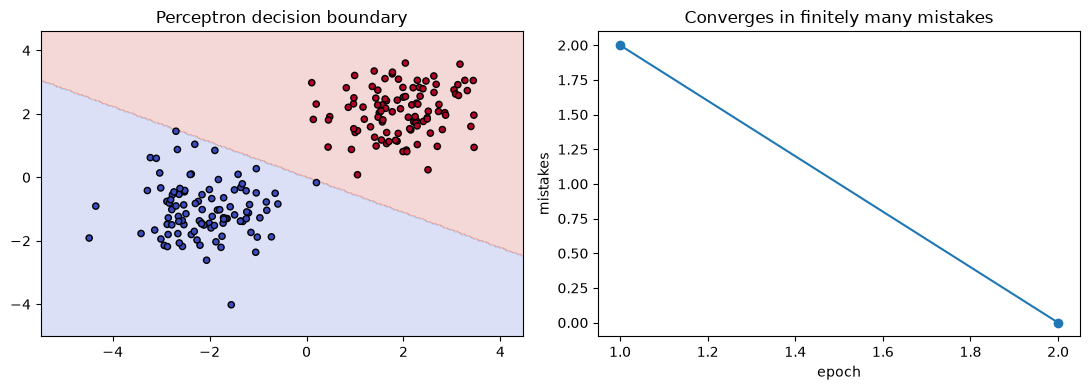

In [3]:
n = 100
X = np.vstack([rng.normal([2, 2], 0.8, (n, 2)), rng.normal([-2, -1], 0.8, (n, 2))])
y = np.array([1] * n + [-1] * n)

p = Perceptron(2)
hist = p.fit(X, y)
print("mistakes per epoch:", hist)
print("training accuracy:", (p.predict(X) == y).mean())

def plot_boundary(ax, model, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.2, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=20)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_boundary(axes[0], p, X, y, "Perceptron decision boundary")
axes[1].plot(range(1, len(hist) + 1), hist, marker="o")
axes[1].set(xlabel="epoch", ylabel="mistakes", title="Converges in finitely many mistakes")
plt.tight_layout(); plt.show()

## Checking the convergence bound
Compute $R$ and the margin $\gamma$ of the best separator we can find, and compare total mistakes with $(R/\gamma)^2$.

In [4]:
Xa = np.c_[X, np.ones(len(X))]                 # fold the bias into the weights
w = np.r_[p.w, p.b]; w /= np.linalg.norm(w)
gamma = (y * (Xa @ w)).min()                     # margin of the learned separator (a lower bound on the best margin)
R = np.linalg.norm(Xa, axis=1).max()
print(f"total mistakes = {sum(hist)},  (R/gamma)^2 = {(R / gamma) ** 2:.1f}  (bound uses the optimal margin, which is >= gamma)")

total mistakes = 2,  (R/gamma)^2 = 15123.9  (bound uses the optimal margin, which is >= gamma)


## Real data: Iris (setosa vs. versicolor)
These two flower species are linearly separable using petal length & width.

epochs: 2 | accuracy: 1.0


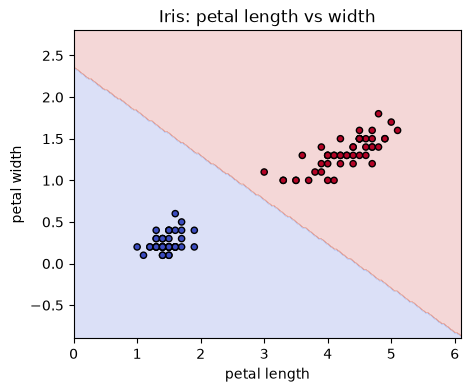

In [5]:
iris = load_iris()
mask = iris.target < 2
Xi = iris.data[mask][:, [2, 3]]
yi = np.where(iris.target[mask] == 0, -1, 1)
pi = Perceptron(2, lr=0.1)
hi = pi.fit(Xi, yi)
print("epochs:", len(hi), "| accuracy:", (pi.predict(Xi) == yi).mean())
fig, ax = plt.subplots(figsize=(5, 4))
plot_boundary(ax, pi, Xi, yi, "Iris: petal length vs width")
ax.set(xlabel="petal length", ylabel="petal width"); plt.show()

## Takeaways
- The first **learning rule**: nudge weights toward misclassified examples.
- Guaranteed to converge — *but only if a separating line exists*. See the 1969 notebook for what happens otherwise.